In [9]:
TRAIN_DIR = "/home/lmalerba/projects/kaggle_challenge_sdi/data/original_dataset_optimized_512px/train/000_Physonectae" 

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import io, color, filters, measure, morphology
from skimage.measure import regionprops_table

# === CONFIGURATION ===
# Mets le chemin vers ton dossier train (ou un sous-dossier de classe)
# TRAIN_DIR = "/chemin/vers/ton/dataset/train/Copepoda" # Exemple plus précis

# Est-ce que tes planctons sont foncés sur fond clair (ZooScan) ? -> True
# Est-ce que tes planctons sont clairs sur fond noir (In-situ) ? -> False
DARK_OBJECT_ON_LIGHT_BG = True 

# === 1. FONCTION DE TRAITEMENT ===
def process_check(img_path):
    # Lecture
    image = io.imread(img_path)
    if image.ndim == 3:
        gray = color.rgb2gray(image)
    else:
        gray = image

    # Segmentation Otsu
    try:
        thresh = filters.threshold_otsu(gray)
    except ValueError:
        return None, None, None # Image unicolore

    # Création du masque binaire
    if DARK_OBJECT_ON_LIGHT_BG:
        binary = gray < thresh  # Objet sombre, fond clair
    else:
        binary = gray > thresh  # Objet clair, fond sombre

    # Nettoyage : On vire les petits bruits (poussières < 50 pixels)
    binary = morphology.remove_small_objects(binary, min_size=50)

    # On ne garde que la plus grosse forme détectée (le plancton principal)
    label_img = measure.label(binary)
    regions = measure.regionprops(label_img, intensity_image=gray)
    
    if not regions:
        return None, None, None
        
    # Trouver le plus gros objet
    best_region = max(regions, key=lambda r: r.area)
    
    # Extraire les données juste pour cet objet
    # On ruse un peu pour utiliser regionprops_table sur une seule region
    # (regionprops_table attend une image labelisée, mais on veut filtrer avant)
    # Donc on extrait manuel ou on refait un masque propre. 
    # Pour ce test rapide, on extrait les props direct du 'best_region'
    
    props = {
        "filename": os.path.basename(img_path),
        "area": best_region.area,
        "perimeter": best_region.perimeter,
        "eccentricity (allongement)": best_region.eccentricity,
        "mean_intensity": best_region.mean_intensity,
        "solidity": best_region.solidity,
        "major_axis": best_region.major_axis_length,
        "minor_axis": best_region.minor_axis_length
    }
    
    return image, binary, props

# === 2. EXECUTION DU TEST SUR 3 IMAGES AU HASARD ===
# Récupération de toutes les images (jpg, png, tif...)
all_images = []
for ext in ['*.jpg', '*.png', '*.jpeg', '*.tif']:
    all_images.extend(glob.glob(os.path.join(TRAIN_DIR, '**', ext), recursive=True))

if len(all_images) == 0:
    print("ERREUR : Aucune image trouvée ! Vérifie le chemin TRAIN_DIR.")
else:
    # On prend 3 images au pif
    sample_images = np.random.choice(all_images, min(3, len(all_images)), replace=False)

    results_data = []

    plt.figure(figsize=(15, 10))
    
    for i, img_path in enumerate(sample_images):
        original, binary, features = process_check(img_path)
        
        if original is None: continue
        
        results_data.append(features)

        # Affichage
        plt.subplot(3, 2, i*2 + 1)
        plt.imshow(original, cmap='gray')
        plt.title(f"Image Originale : {os.path.basename(img_path)}")
        plt.axis('off')

        plt.subplot(3, 2, i*2 + 2)
        plt.imshow(binary, cmap='gray') # Noir et Blanc
        plt.title(f"Masque Otsu (Ce que l'algo voit)")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

    # === AFFICHER LES DATA ===
    print("\n=== VOICI LES FEATURES EXTRAITES ===")
    df = pd.DataFrame(results_data)
    display(df) # Si tu es dans Jupyter, ça affiche un joli tableau


ERREUR : Aucune image trouvée ! Vérifie le chemin TRAIN_DIR.


ça a l'air de bien fonctionner donc on va plus loin

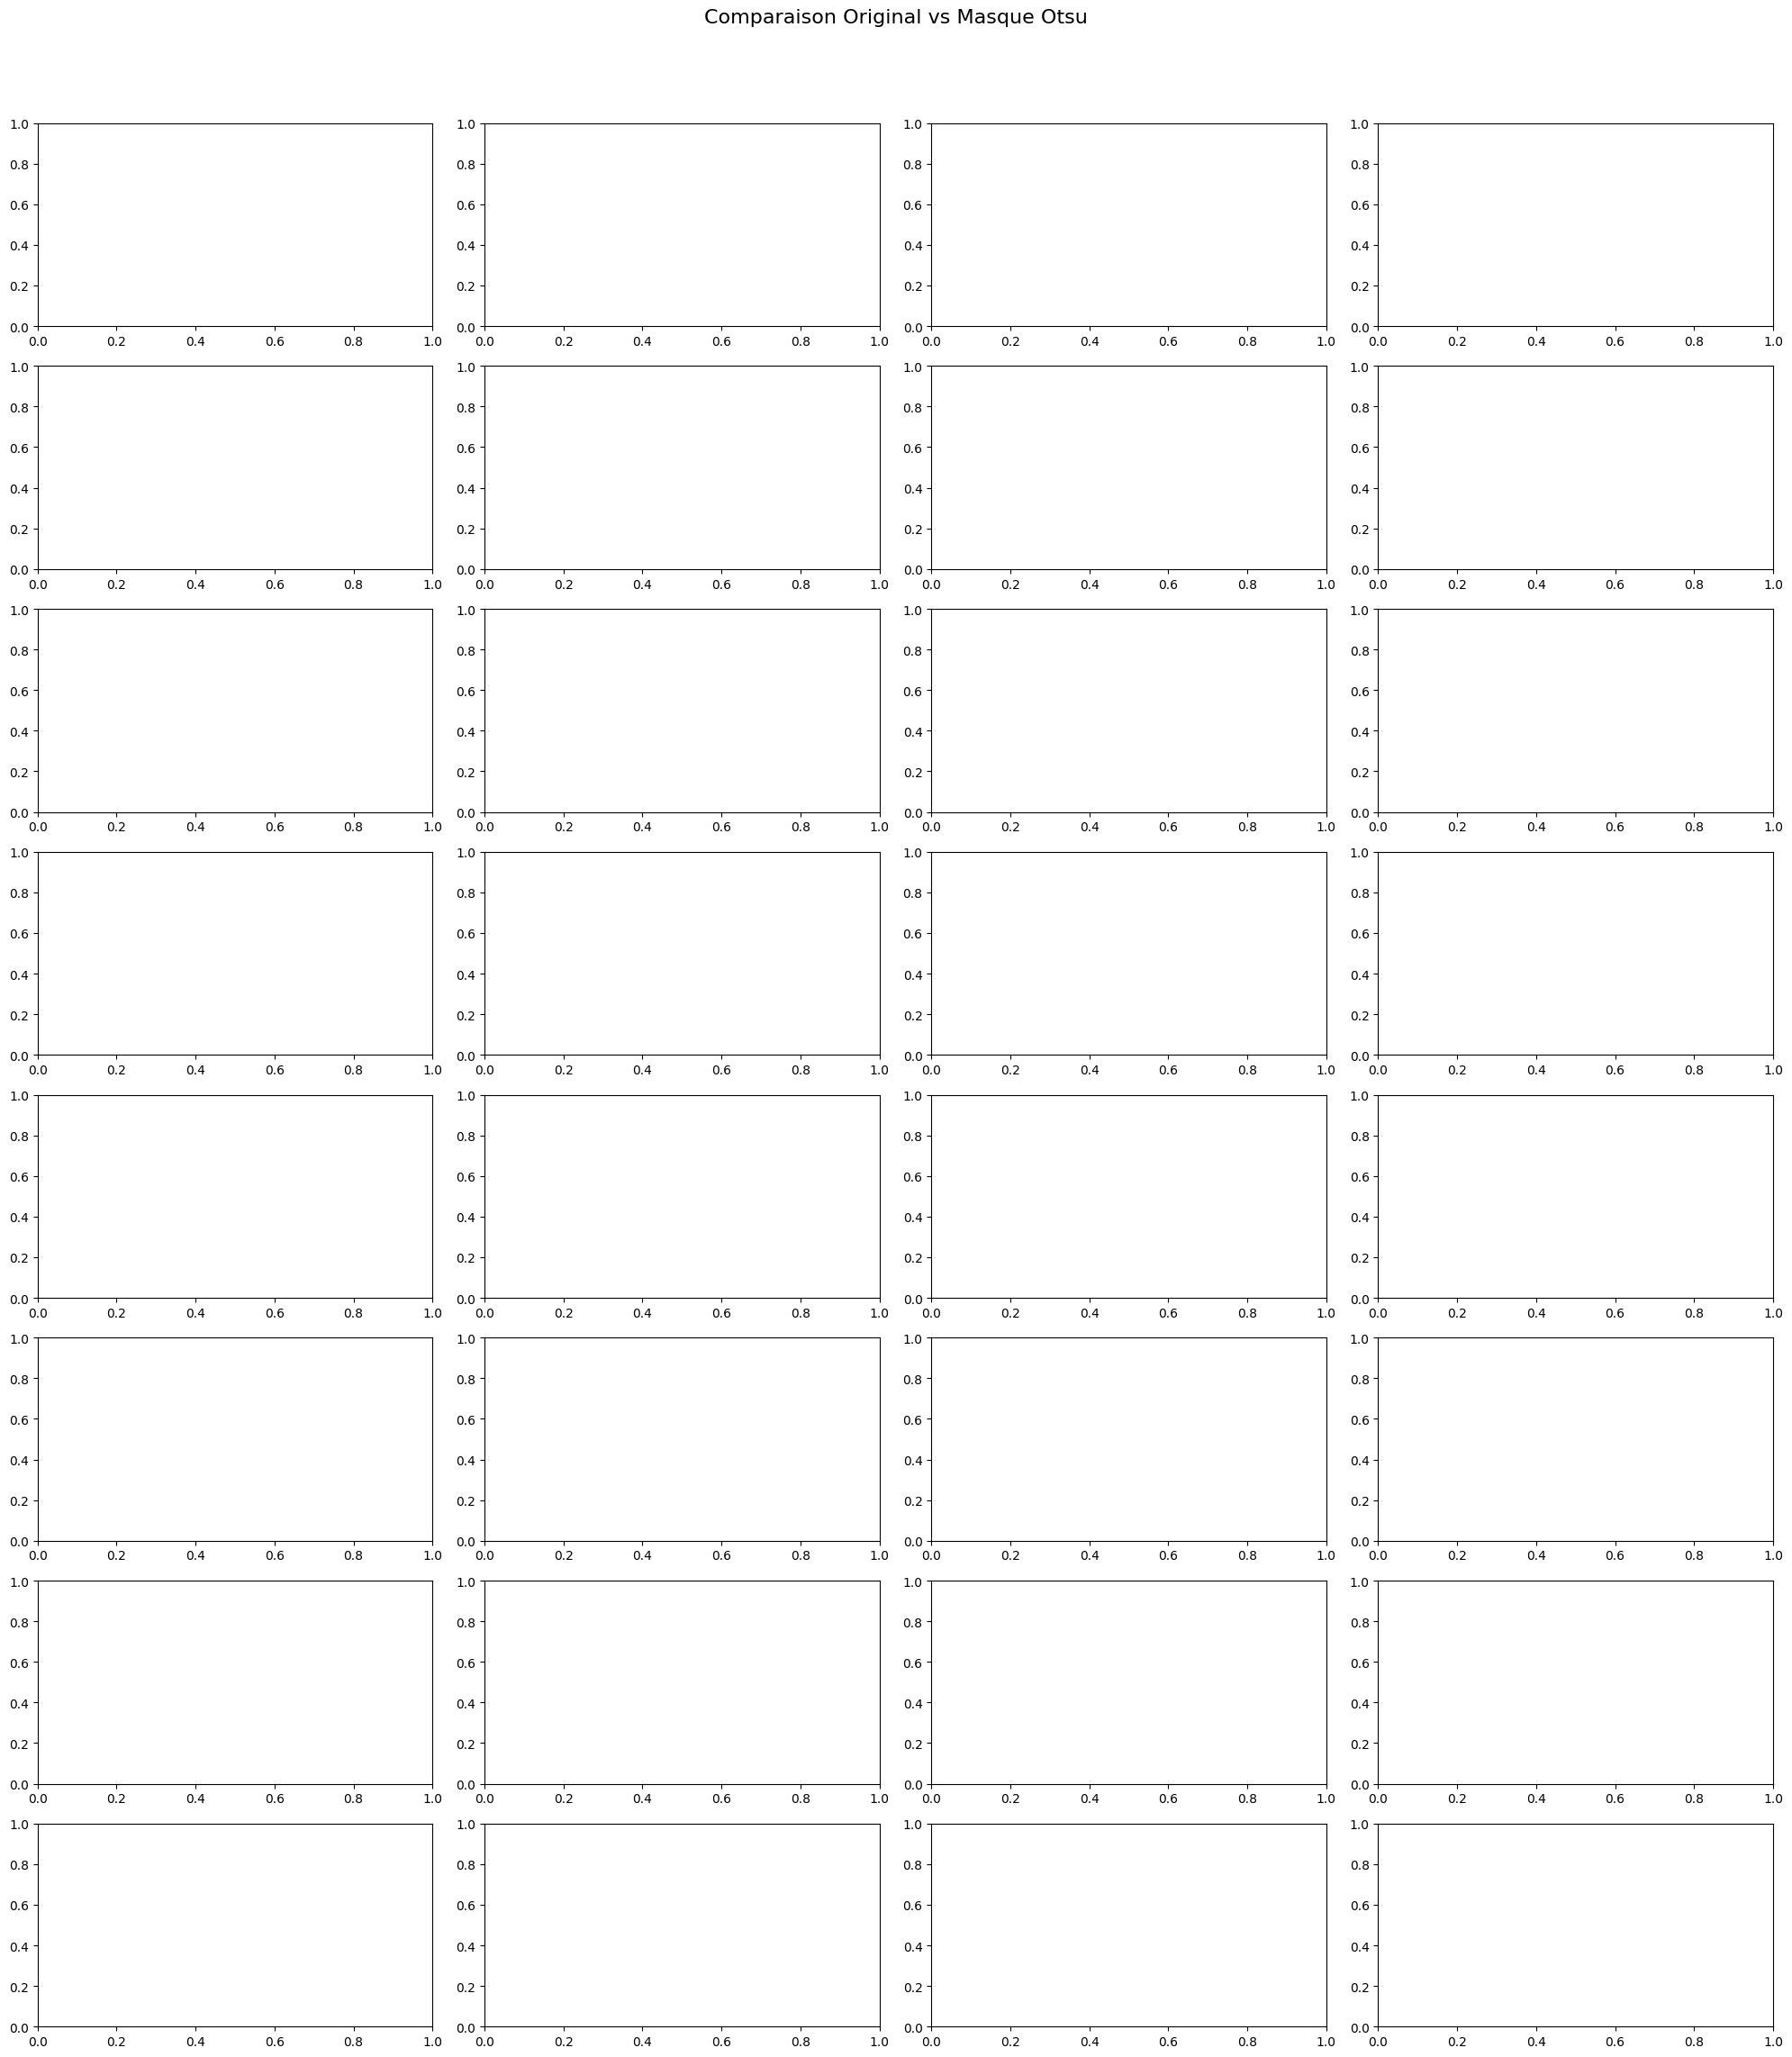

In [7]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, filters, morphology

DARK_OBJECT = True 

# === FONCTION ===
def get_visu_pair(img_path):
    try:
        img = io.imread(img_path)
        if img.ndim == 3:
            gray = color.rgb2gray(img)
        else:
            gray = img
        
        # Segmentation
        val = filters.threshold_otsu(gray)
        mask = gray < val if DARK_OBJECT else gray > val
        mask = morphology.remove_small_objects(mask, min_size=50)
        
        return img, mask, os.path.basename(img_path)
    except:
        return None, None, None

# === AFFICHAGE ===
all_files = glob.glob(os.path.join(TRAIN_DIR, "**", "*.jpg"), recursive=True) + \
            glob.glob(os.path.join(TRAIN_DIR, "**", "*.png"), recursive=True)

# On prend 32 images au hasard (pour faire 8 lignes de 4 paires)
subset = np.random.choice(all_files, min(32, len(all_files)), replace=False)

fig, axes = plt.subplots(8, 4, figsize=(20, 24)) # 8 lignes, 4 colonnes de paires
fig.suptitle("Comparaison Original vs Masque Otsu", fontsize=16)

# On supprime les axes vides si besoin
axes = axes.ravel()

index_plot = 0
for img_path in subset:
    orig, mask, name = get_visu_pair(img_path)
    
    if orig is not None:
        # Création d'une sous-figure composée (Original | Masque)
        # Astuce : on colle les images côte à côte numpy pour l'affichage
        
        # Redimensionner le masque pour qu'il ait 3 canaux pour l'affichage collé si orig est RGB
        if orig.ndim == 3:
            mask_visu = np.stack([mask]*3, axis=-1) * 255 # Conversion en RGB (Noir/Blanc)
            if orig.dtype == np.uint8: mask_visu = mask_visu.astype(np.uint8)
        else:
            mask_visu = mask * 255
            
        # Collage horizontal
        combined = np.hstack((orig, mask_visu))
        
        axes[index_plot].imshow(combined, cmap='gray' if orig.ndim==2 else None)
        axes[index_plot].set_title(name[:15], fontsize=8)
        axes[index_plot].axis('off')
        index_plot += 1

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()



In [8]:
import pandas as pd
from skimage import measure, feature
from scipy import stats
from matplotlib.patches import Ellipse

# === CHOISIS UNE IMAGE (OU LAISSE AU HASARD) ===
# target_image = "chemin/vers/ton/image.jpg" 
target_image = np.random.choice(all_files) # Image au hasard

print(f"Inspection de : {target_image}")

# === FONCTION D'ANALYSE UNIQUE ===
def analyze_and_show(img_path):
    # 1. Traitement
    img = io.imread(img_path)
    if img.ndim == 3:
        gray = color.rgb2gray(img)
        gray_uint = (gray * 255).astype(np.uint8)
    else:
        gray_uint = img
        gray = img / 255.0

    val = filters.threshold_otsu(gray)
    mask = gray < val if DARK_OBJECT else gray > val
    mask = morphology.remove_small_objects(mask, min_size=50)
    
    label_img = measure.label(mask)
    regions = measure.regionprops(label_img, intensity_image=gray_uint)
    
    if not regions:
        print("Rien détecté sur cette image !")
        plt.imshow(img)
        return

    # On prend la plus grosse région
    props = max(regions, key=lambda r: r.area)
    
    # === CALCULS (Extrait) ===
    feat = {
        'label': os.path.basename(os.path.dirname(img_path)),
        'area': props.area,
        'perimeter': f"{props.perimeter:.2f}",
        'major_axis': f"{props.major_axis_length:.2f}",
        'minor_axis': f"{props.minor_axis_length:.2f}",
        'elongation': f"{props.major_axis_length / (props.minor_axis_length+1):.2f}",
        'circularity': f"{(4 * np.pi * props.area) / (props.perimeter**2):.2f}",
        'mean_grey': f"{props.mean_intensity:.2f}",
        'solidity': f"{props.solidity:.2f}",
        'convex_area': props.convex_area
    }

    # === AFFICHAGE GRAPHIQUE ===
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    
    # Image originale
    ax1.imshow(img, cmap='gray')
    ax1.set_title("Image Originale")
    ax1.axis('off')
    
    # Masque avec Annotations Mathématiques
    ax2.imshow(mask, cmap='gray')
    ax2.set_title("Masque + Ellipse (Maths)")
    
    # Dessiner l'ellipse approximée (ce qui sert à calculer Breadth/Length)
    y0, x0 = props.centroid
    orientation = props.orientation
    x1 = x0 + np.cos(orientation) * 0.5 * props.minor_axis_length
    y1 = y0 - np.sin(orientation) * 0.5 * props.minor_axis_length
    x2 = x0 - np.sin(orientation) * 0.5 * props.major_axis_length
    y2 = y0 - np.cos(orientation) * 0.5 * props.major_axis_length

    # Ellipse en rouge
    ellipse = Ellipse((x0, y0), width=props.minor_axis_length, height=props.major_axis_length,
                      angle=np.rad2deg(-orientation), edgecolor='red', facecolor='none', linewidth=2)
    ax2.add_patch(ellipse)
    
    # Centre de gravité (point bleu)
    ax2.plot(x0, y0, '.b', markersize=10)
    ax2.axis('off')
    
    plt.show()
    
    # === AFFICHAGE DONNÉES ===
    print("--- caractéristiques calculées ---")
    df_res = pd.DataFrame([feat])
    display(df_res.T) # Transposé pour lire verticalement

# Execute
analyze_and_show(target_image)



ValueError: 'a' cannot be empty unless no samples are taken

Génération du comparatif sur 32 images...


  0%|          | 0/32 [00:00<?, ?it/s]/tmp/ipykernel_104671/546450851.py:65: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  clean_otsu = morphology.remove_small_objects(mask_otsu, 50)
/tmp/ipykernel_104671/546450851.py:66: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  clean_relax = morphology.remove_small_objects(

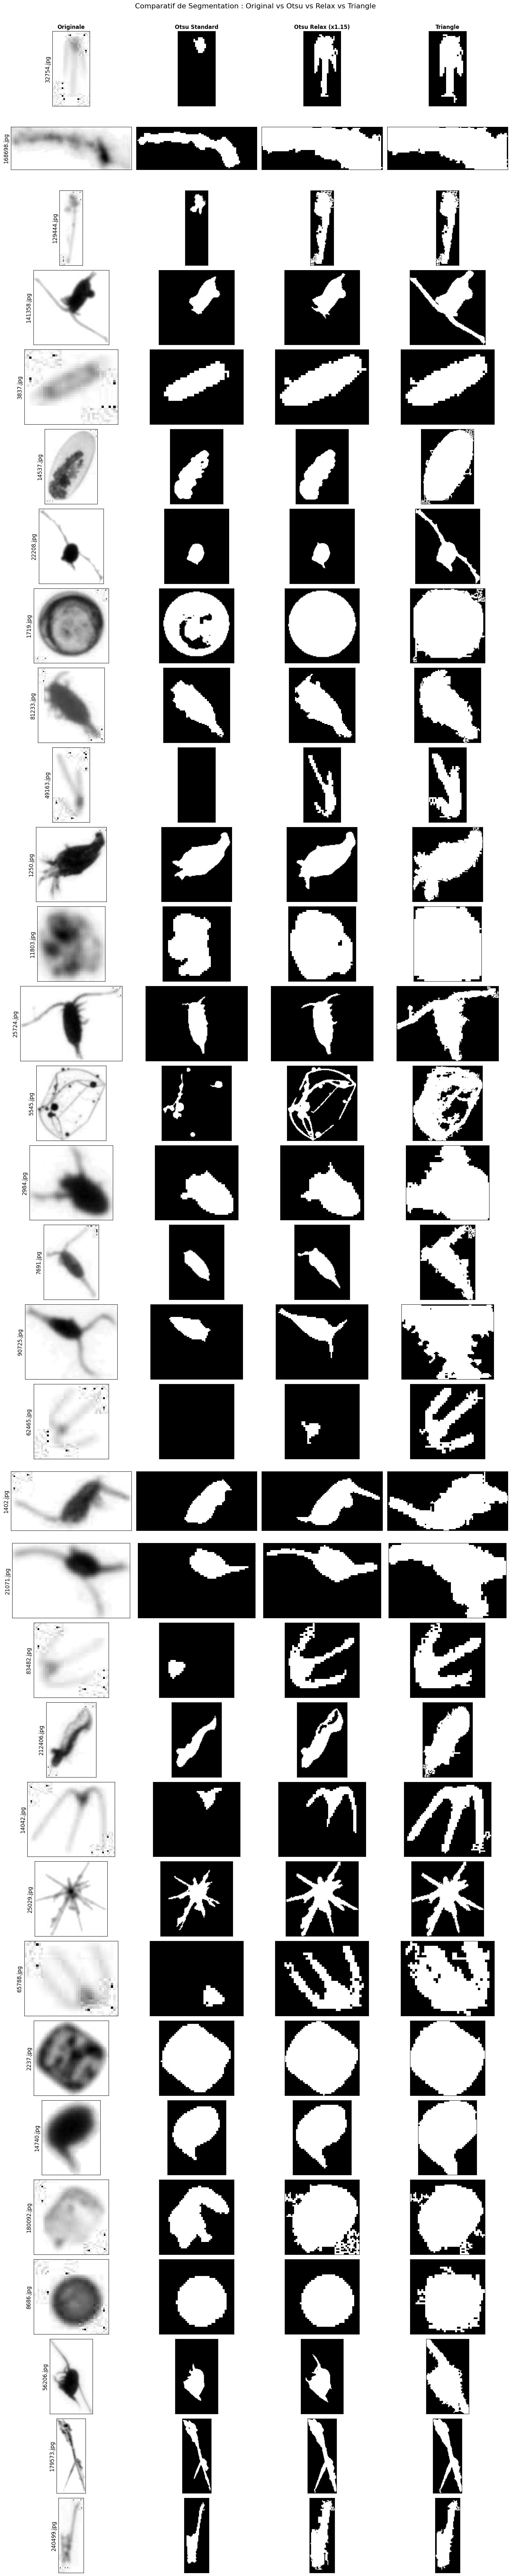

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, filters, morphology
from tqdm import tqdm # Barre de progression optionnelle

# === CONFIGURATION ===
DARK_OBJECT = True 
PERMISSIVITE = 1.15 # 1.15 = On augmente le seuil de 15% pour attraper les gris clairs (pattes, etc)
NB_IMAGES = 32

# === PRÉPARATION ===
all_files = glob.glob(os.path.join(TRAIN_DIR, "**", "*.jpg"), recursive=True) + \
            glob.glob(os.path.join(TRAIN_DIR, "**", "*.png"), recursive=True)

# Choix aléatoire
if len(all_files) > NB_IMAGES:
    subset = np.random.choice(all_files, NB_IMAGES, replace=False)
else:
    subset = all_files

print(f"Génération du comparatif sur {len(subset)} images...")

# === FIGURE GÉANTE (32 lignes x 4 colonnes) ===
# On prévoit ~2.5 pouces de hauteur par image -> 32*2.5 = 80 pouces de haut
fig, axes = plt.subplots(len(subset), 4, figsize=(16, len(subset) * 2.5))
fig.suptitle(f"Comparatif de Segmentation : Original vs Otsu vs Relax vs Triangle", fontsize=16, y=1.002)

for i, img_path in enumerate(tqdm(subset)):
    # 1. Chargement & Gris
    try:
        img = io.imread(img_path)
        if img.ndim == 3:
            gray = color.rgb2gray(img)
        else:
            gray = img
            # Si image en entier (0-255), on normalise souvent pour Otsu/Scikit
            if gray.dtype == np.uint8:
                gray = gray / 255.0

        # --- A. OTSU CLASSIQUE ---
        val_otsu = filters.threshold_otsu(gray)
        mask_otsu = gray < val_otsu if DARK_OBJECT else gray > val_otsu

        # --- B. OTSU RELAX (Boosté) ---
        # Si objet sombre : on veut inclure plus de gris -> on AUGMENTE le seuil (vers le blanc 1.0)
        if DARK_OBJECT:
            # On monte le seuil de 15%, plafonné à 1.0
            val_relax = min(val_otsu * PERMISSIVITE, 0.99)
            mask_relax = gray < val_relax
        else:
            # Si objet clair : on baisse le seuil
            val_relax = max(val_otsu * (2 - PERMISSIVITE), 0.01)
            mask_relax = gray > val_relax

        # --- C. TRIANGLE ---
        try:
            val_tri = filters.threshold_triangle(gray)
            mask_tri = gray < val_tri if DARK_OBJECT else gray > val_tri
        except:
            mask_tri = mask_otsu # Fallback

        # Nettoyage commun (enlever petits bruits)
        clean_otsu = morphology.remove_small_objects(mask_otsu, 50)
        clean_relax = morphology.remove_small_objects(mask_relax, 50)
        clean_tri = morphology.remove_small_objects(mask_tri, 50)

        # --- AFFICHAGE LIGNE PAR LIGNE ---
        ax_row = axes[i]
        
        # Col 1 : Originale
        ax_row[0].imshow(img, cmap='gray')
        if i == 0: ax_row[0].set_title("Originale", fontsize=12, fontweight='bold')
        ax_row[0].set_ylabel(os.path.basename(img_path)[:15], rotation=90, size='large') # Nom partiel fichier
        
        # Col 2 : Otsu Std
        ax_row[1].imshow(clean_otsu, cmap='gray')
        if i == 0: ax_row[1].set_title("Otsu Standard", fontsize=12, fontweight='bold')
        
        # Col 3 : Otsu Relax
        ax_row[2].imshow(clean_relax, cmap='gray')
        if i == 0: ax_row[2].set_title(f"Otsu Relax (x{PERMISSIVITE})", fontsize=12, fontweight='bold')
        
        # Col 4 : Triangle
        ax_row[3].imshow(clean_tri, cmap='gray')
        if i == 0: ax_row[3].set_title("Triangle", fontsize=12, fontweight='bold')

    except Exception as e:
        print(f"Erreur sur {img_path}: {e}")

# Retirer les axes (ticks) pour propreté
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()


In [ ]:
!pip install rembg onnxruntime


Chargement du modèle IA et traitement de 16 images...



  0%|          | 0/16 [00:00<?, ?it/s]Downloading data from 'https://github.com/danielgatis/rembg/releases/download/v0.0.0/u2net.onnx' to file '/home/lmalerba/.u2net/u2net.onnx'.
100%|███████████████████████████████████████| 176M/176M [00:00<00:00, 96.5GB/s]
100%|██████████| 16/16 [00:19<00:00,  1.23s/it]


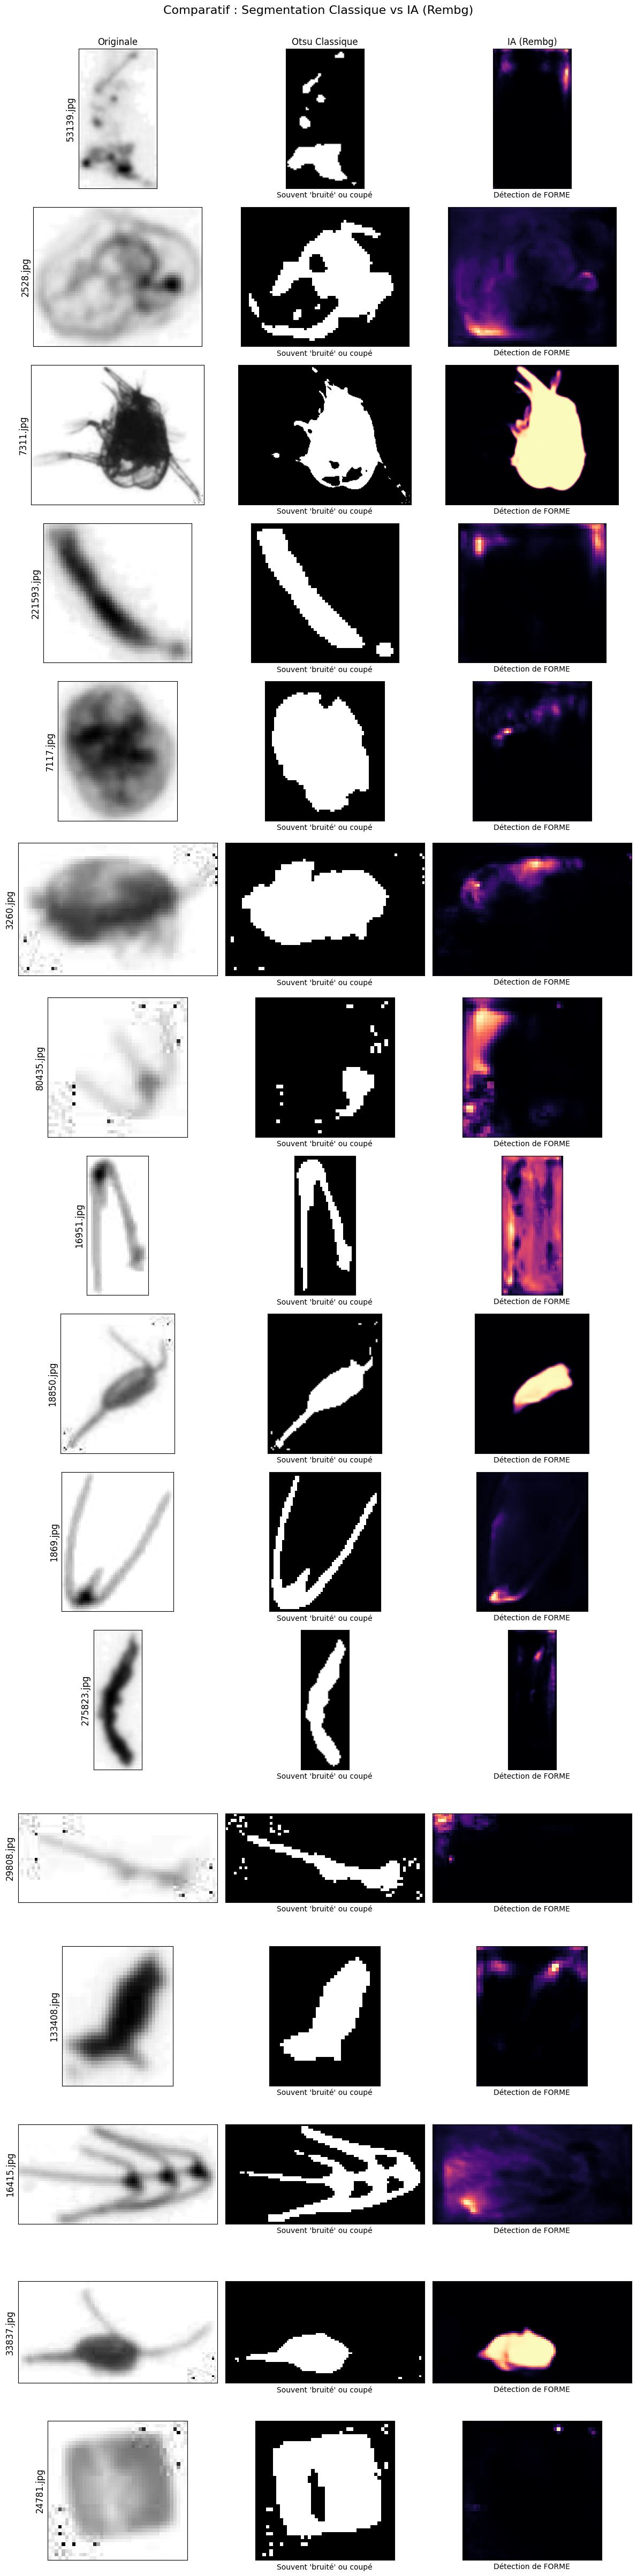

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from rembg import remove
from skimage import color, filters, io
from tqdm import tqdm

# === CONFIGURATION ===
NB_IMAGES = 16  # On en met un peu moins car c'est plus lent que Otsu

# Récupération des fichiers
all_files = glob.glob(os.path.join(TRAIN_DIR, "**", "*.jpg"), recursive=True)
if len(all_files) > NB_IMAGES:
    subset = np.random.choice(all_files, NB_IMAGES, replace=False)
else:
    subset = all_files

print(f"Chargement du modèle IA et traitement de {len(subset)} images...\n")

# Configuration de l'affichage (1 ligne par image, 3 colonnes)
fig, axes = plt.subplots(len(subset), 3, figsize=(12, len(subset) * 3))
fig.suptitle("Comparatif : Segmentation Classique vs IA (Rembg)", fontsize=16, y=1.002)

for i, img_path in enumerate(tqdm(subset)):
    # 1. Chargement (PIL pour Rembg, Numpy pour Scikit-image)
    pil_img = Image.open(img_path)
    np_img = io.imread(img_path)
    
    # Version Grise pour Otsu
    if np_img.ndim == 3: gray = color.rgb2gray(np_img)
    else: gray = np_img

    # --- MÉTHODE 1 : OTSU (L'ancienne) ---
    try:
        thresh = filters.threshold_otsu(gray)
        mask_otsu = gray < thresh
    except:
        mask_otsu = np.zeros_like(gray) # Si image unie

    # --- MÉTHODE 2 : REMBG (L'IA) ---
    # remove renvoie une image RGBA. Le canal A (Alpha) est le masque.
    try:
        output_rembg = remove(pil_img)
        output_np = np.array(output_rembg)
        # On récupère le canal 4 (Alpha) : c'est notre masque
        mask_ai = output_np[:, :, 3] # 0-255
    except Exception as e:
        print(f"Erreur IA sur {img_path}: {e}")
        mask_ai = np.zeros_like(gray)

    # --- AFFICHAGE ---
    ax = axes[i]
    
    # Col 1: Originale
    ax[0].imshow(np_img, cmap='gray')
    ax[0].set_ylabel(os.path.basename(img_path)[:15], rotation=90, size='large')
    if i == 0: ax[0].set_title("Originale")
    
    # Col 2: Otsu (Classique)
    ax[1].imshow(mask_otsu, cmap='gray')
    ax[1].set_xlabel("Souvent 'bruité' ou coupé")
    if i == 0: ax[1].set_title("Otsu Classique")
    
    # Col 3: Rembg (IA)
    ax[2].imshow(mask_ai, cmap='magma') # En couleur pour voir les niveaux de confiance
    ax[2].set_xlabel("Détection de FORME")
    if i == 0: ax[2].set_title("IA (Rembg)")

# Nettoyage
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()


In [ ]:
!pip install git+https://github.com/facebookresearch/segment-anything.git
!pip install opencv-python pycocotools matplotlib onnxruntime onnx

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-ap5qpg0u
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-ap5qpg0u
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
  DEPRECATION: Building 'segment_anything' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'segment_anything'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36635 sha256=1c15dce7ef04e1bf1c07dc0

Traitement en mode 'Guidé par le centre'...


100%|██████████| 8/8 [00:01<00:00,  4.51it/s]


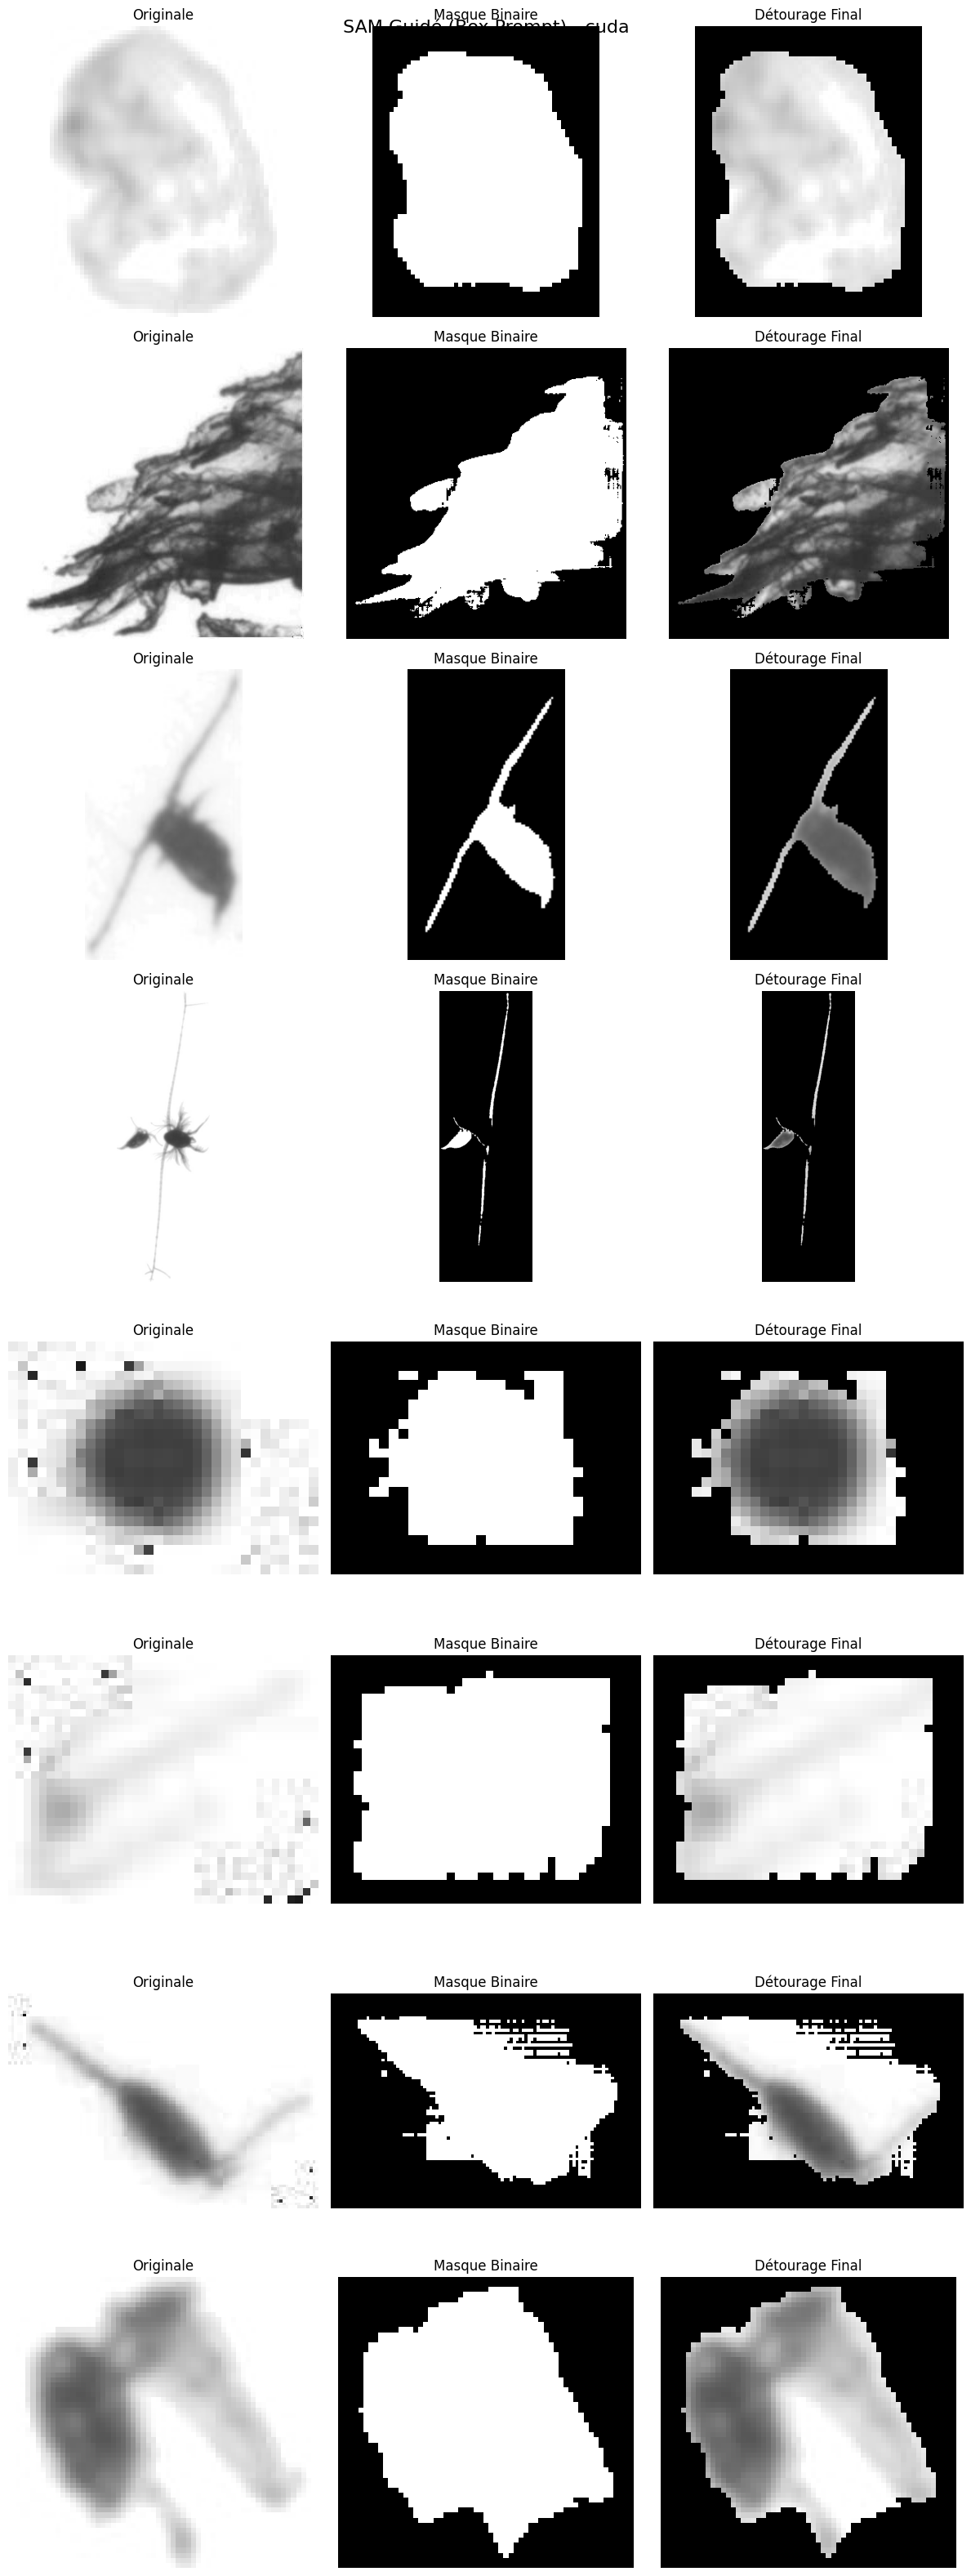

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import glob
from segment_anything import sam_model_registry, SamPredictor
from tqdm import tqdm

# === CONFIGURATION ===
# TRAIN_DIR = "./data_reannotated/train"
NB_IMAGES = 8
MODEL_TYPE = "vit_b"
CHECKPOINT_PATH = "sam_vit_b_01ec64.pth"

# 1. Chargement du modèle (Mode Predictor cette fois)
device = "cuda" if torch.cuda.is_available() else "cpu"
sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH)
sam.to(device=device)

predictor = SamPredictor(sam) # On utilise le "Predictor" pas le "Generator"

# 2. Récupération des images
all_files = glob.glob(os.path.join(TRAIN_DIR, "**", "*.jpg"), recursive=True)
subset = np.random.choice(all_files, NB_IMAGES, replace=False) if len(all_files) > NB_IMAGES else all_files

# 3. Affichage
fig, axes = plt.subplots(len(subset), 3, figsize=(12, len(subset) * 4))
fig.suptitle(f"SAM Guidé (Box Prompt) - {device}", fontsize=16)

print("Traitement en mode 'Guidé par le centre'...")

for i, img_path in enumerate(tqdm(subset)):
    # Lecture image
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape

    # --- LA STRATÉGIE "SNIPER" ---
    # On définit une "boîte" qui couvre le centre de l'image (on ignore les bords extrêmes)
    # L'IA va chercher l'objet dominant DANS cette boite.
    box = np.array([
        w * 0.1,  # x_min (si on enlève 10% à gauche)
        h * 0.1,  # y_min (si on enlève 10% en haut)
        w * 0.9,  # x_max
        h * 0.9   # y_max
    ])

    # Préparation de l'IA sur cette image
    predictor.set_image(image)

    # Prédiction avec la boite comme indice
    masks, scores, logits = predictor.predict(
        box=box[None, :],
        multimask_output=False # On veut juste le meilleur masque possible
    )
    
    # Le résultat
    best_mask = masks[0] 

    # Création du détourage propre (Fond noir)
    cutout = image.copy()
    cutout[~best_mask] = 0 # Tout ce qui n'est pas le masque devient noir

    # --- AFFICHAGE ---
    ax = axes[i] if len(subset) > 1 else axes
    
    # 1. Originale
    ax[0].imshow(image)
    ax[0].set_title("Originale")
    ax[0].axis('off')
    
    # 2. Le Masque (Noir et Blanc)
    ax[1].imshow(best_mask, cmap='gray')
    ax[1].set_title("Masque Binaire")
    ax[1].axis('off')
    
    # 3. Résultat découpé
    ax[2].imshow(cutout)
    ax[2].set_title("Détourage Final")
    ax[2].axis('off')

plt.tight_layout()
plt.show()
